# 03 · Training curves

Every run in `data/results/arch_v1/`, all trained on the GPU by `model/gpu_train.py`.
Re-run all to refresh; unfinished runs show up in the progress list below.

**How to read the curves**

**Columns:** one per architecture. **Colour:** darker = bigger model (5 sizes, ~4× parameters apart).

* **Row 1, loss.**
  * Train loss is the mean over the last 250 steps; val loss is on held-out *simulated*
    positives plus negative windows.
  * A val loss that rises while train loss falls is overfitting.
* **Row 2, val FRR.**
  * Missed held-out TTS keywords at a threshold giving 1 false alarm/h on held-out
    simulated conversation.
  * This half of the simulator holdout (`val`) is what early stopping looks at.
  * The ★ marks the checkpoint that was kept.
* **Row 3, the real-world monitor.** Never used for any decision.
  * Solid: missed **real** keywords (Common Voice speakers in real rooms) at the same
    threshold.
  * Dashed, right axis: false alarms/h on 5 h of **real meetings** (AMI).
  * If sim validation is a good proxy, solid row-3 lines move with row 2.

Early stopping: validation every 250 steps; stop after 8 validations (2,000 steps) without
improvement in mean val FRR at 0.5/1/2 FA/h.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from nbutil import ARCH_COLOR, ARCH_ORDER, load_runs, progress

progress()
runs = load_runs("arch_v3")
words = sorted({r["slug"] for r in runs})
print(f"\n{len(runs)} finished runs; words: {words}")

telescope_gru            gru:43 step 2500 train 0.879 val_loss 0.432 val_score 0.873 real 0.897 ami 0.00/h (368s) *
telescope_mingru         mingru:86 step 1000 train 1.317 val_loss 1.005 val_score 1.000 real 1.000 ami 0.00/h (63s)
telescope_tcn            tcn:16 step 2000 train 0.990 val_loss 0.666 val_score 0.833 real 0.915 ami 0.40/h (345s)
telescope_transformer    transformer:10 step 7250 train 0.955 val_loss 0.528 val_score 0.824 real 0.920 ami 0.00/h (368s)

1 finished runs; words: ['telescope']


/tmp/ipykernel_157579/3372155853.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_v.legend(fontsize=7, loc="lower left")


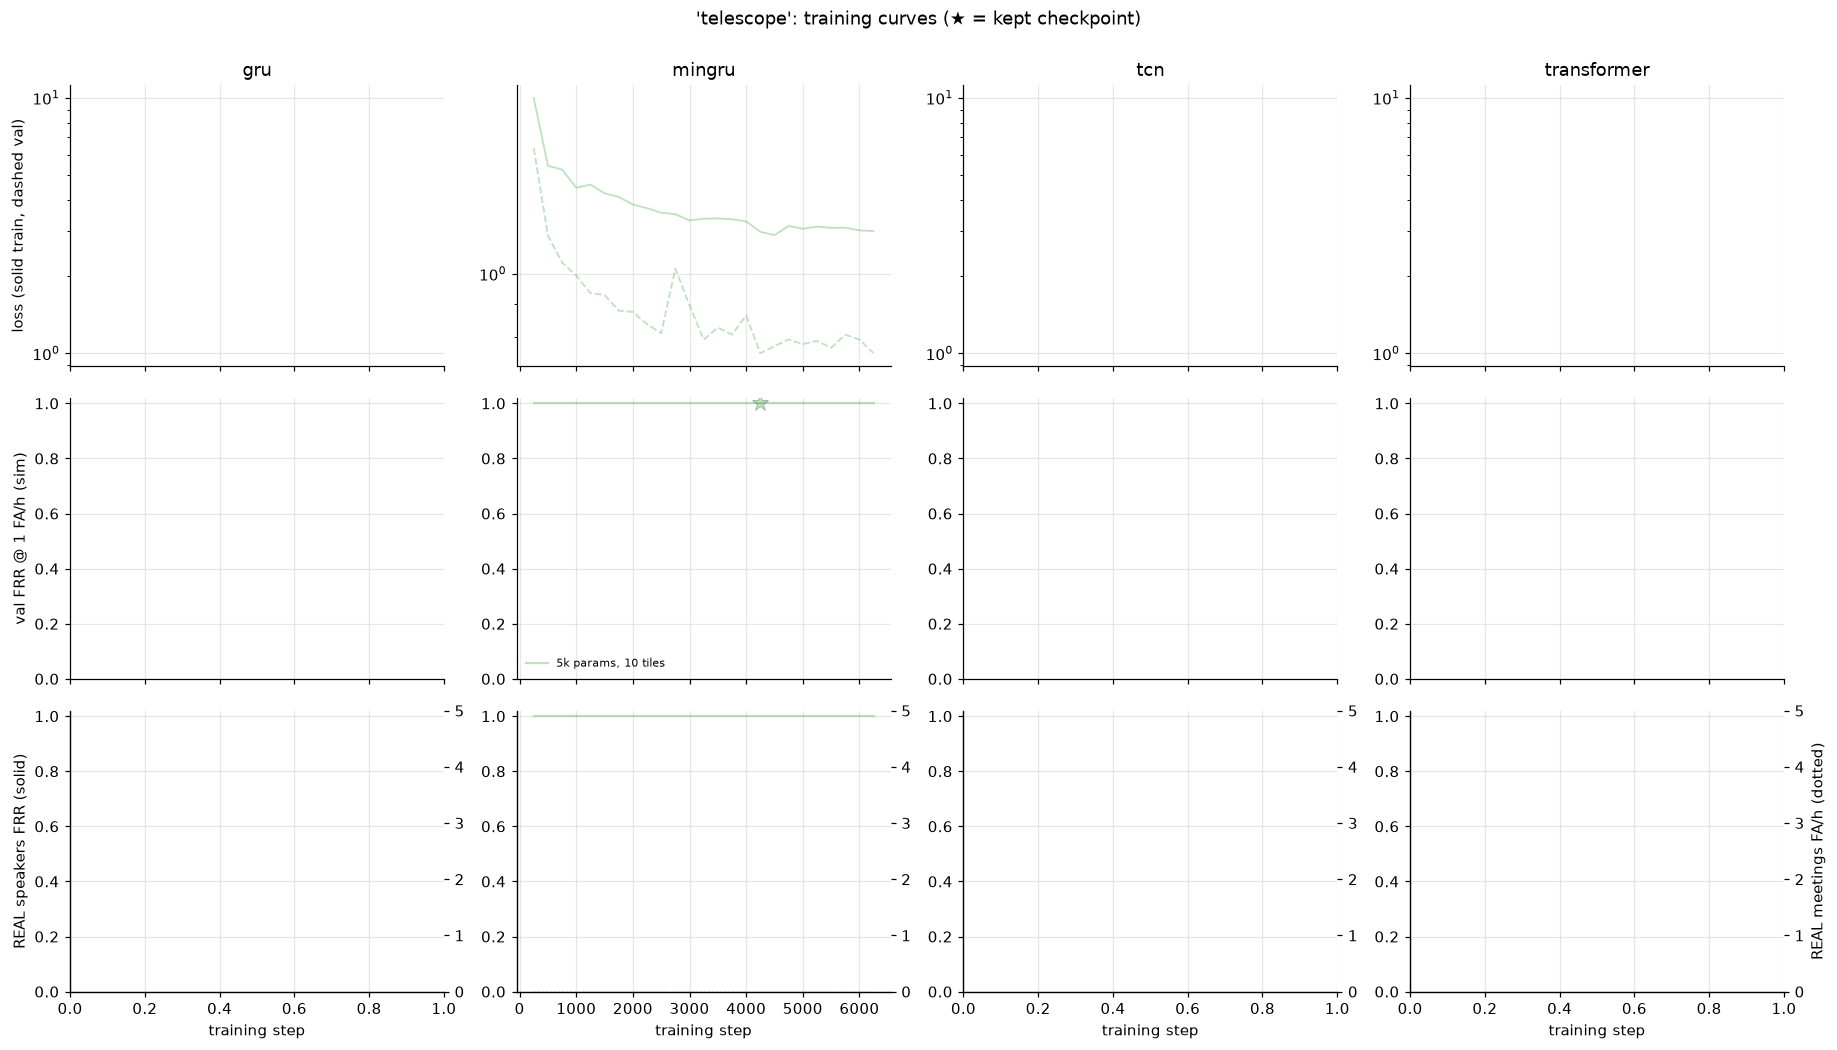

In [2]:
def curves(word):
    rs = [r for r in runs if r["slug"] == word]
    fig, axes = plt.subplots(3, len(ARCH_ORDER), figsize=(4.2 * len(ARCH_ORDER), 9.5), sharex="col")
    for j, arch in enumerate(ARCH_ORDER):
        ax_l, ax_v, ax_r = axes[:, j]
        ax_r2 = ax_r.twinx()
        for r in sorted([r for r in rs if r["arch"] == arch], key=lambda r: r["params"]):
            c = r["curve"]
            st = np.array([x["step"] for x in c])
            col = ARCH_COLOR[arch]
            a = 0.3 + 0.7 * r["size_index"] / 4
            lab = f"{r['params'] / 1e3:.0f}k params, {r['tiles']:.0f} tiles"
            ax_l.plot(st, [x["train_loss"] for x in c], color=col, alpha=a, lw=1.2)
            ax_l.plot(st, [x["val_loss"] for x in c], color=col, alpha=a, lw=1.2, ls="--")
            ax_v.plot(st, [x["val_frr@1.0"] for x in c], color=col, alpha=a, lw=1.5, label=lab)
            b = [x for x in c if x["step"] == r["best_step"]]
            if b:
                ax_v.plot(b[0]["step"], b[0]["val_frr@1.0"], "*", color=col, ms=11, alpha=a, mec="k", mew=0.5)
            ax_r.plot(st, [x.get("mon_frr_real@1.0", np.nan) for x in c], color=col, alpha=a, lw=1.5)
            ax_r2.plot(st, [x["mon_fa_ami@1.0"] for x in c], color=col, alpha=a, lw=1, ls=":")
        ax_l.set(title=arch, yscale="log")
        ax_v.set(ylim=(0, 1.02))
        ax_r.set(ylim=(0, 1.02), xlabel="training step")
        ax_r2.set(ylim=(0, 5))
        ax_r2.grid(False)
        ax_v.legend(fontsize=7, loc="lower left")
        if j == 0:
            ax_l.set_ylabel("loss (solid train, dashed val)")
            ax_v.set_ylabel("val FRR @ 1 FA/h (sim)")
            ax_r.set_ylabel("REAL speakers FRR (solid)")
        if j == len(ARCH_ORDER) - 1:
            ax_r2.set_ylabel("REAL meetings FA/h (dotted)")
    fig.suptitle(f"'{word}': training curves (★ = kept checkpoint)", y=1.0)
    plt.tight_layout()


for w in words:
    curves(w)

## Does simulator validation track reality?

Each point is one validation of one run: sim val FRR (x) vs the real-speaker FRR at the
same threshold (y).
* Points near the diagonal mean the simulator is a faithful stand-in.
* Points above it mean real voices are harder than TTS voices; the gap is what better
  simulation has to close.
* A tight band means sim val is a usable proxy for choosing checkpoints and models.

correlation sim-val vs real: nan; mean real - sim: +0.000


/home/work/Projects/tinytapeout_allwaysOn_audio/.venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


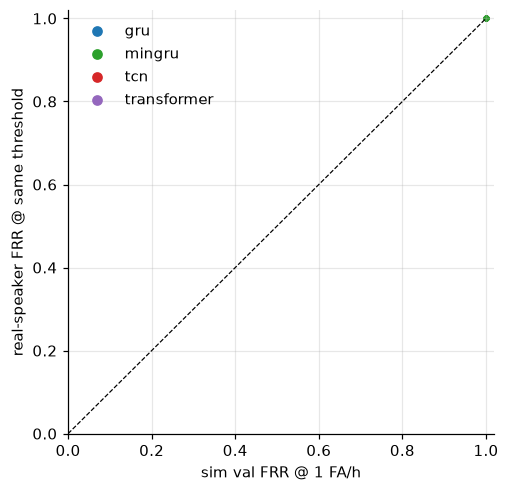

In [3]:
fig, ax = plt.subplots(figsize=(5, 5))
for r in runs:
    c = r["curve"]
    ax.scatter([x["val_frr@1.0"] for x in c], [x.get("mon_frr_real@1.0", np.nan) for x in c],
               s=8, color=ARCH_COLOR[r["arch"]], alpha=0.5)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
for a in ARCH_ORDER:
    ax.scatter([], [], color=ARCH_COLOR[a], label=a)
ax.set(xlabel="sim val FRR @ 1 FA/h", ylabel="real-speaker FRR @ same threshold", xlim=(0, 1.02), ylim=(0, 1.02))
ax.legend()
if runs:
    x = np.concatenate([[p["val_frr@1.0"] for p in r["curve"]] for r in runs])
    y = np.concatenate([[p.get("mon_frr_real@1.0", np.nan) for p in r["curve"]] for r in runs])
    ok = ~np.isnan(y)
    print(f"correlation sim-val vs real: {np.corrcoef(x[ok], y[ok])[0, 1]:.2f}; mean real - sim: {np.mean(y[ok] - x[ok]):+.3f}")

## Cost of training

Wall-clock per run on the Radeon 8060S. Other jobs share the machine, so treat these as
rough. Recurrent models are slow on GPUs because their 100 time steps run one after another.

In [4]:
for r in sorted(runs, key=lambda r: (r["slug"], ARCH_ORDER.index(r["arch"]), r["params"])):
    print(f"{r['slug']:10s} {r['arch']:12s} {r['params']:8d} params: best step {r['best_step']:5d}, "
          f"stopped {r['stopped_step']:5d}, {r['train_time_s'] / 60:5.1f} min")

telescope  mingru           5290 params: best step  4250, stopped  6250,   4.8 min
